## NBA Pred

The goal of this project is to combine my love for the sport of basketball and nba with my thirst to learn about AI and ML. I aim to create 

In [1]:
import pandas
import numpy
import matplotlib
import matplotlib.pyplot as plt
from fetch_raw import fetch_all, load_all_career_stats, load_all_awards

pandas.set_option('display.max_columns', None)

To form the training dataset we are going to follow a simple pipeline:

load -> inspect -> clean -> analyze -> visualise

# Goals

- get all players who played at least 4 seasons from 2000 - 2020
- create a set where each player's season lists his stats and awards
- if not given calculate each player's +/- per season
- segment the set into files with one dimensional arrays representing player seasons:
    3 seasons in the input file
    1 season in the output file


In [2]:
career_stats_df = load_all_career_stats()
career_stats_df

,PLAYER_ID,SEASON_ID,LEAGUE_ID,TEAM_ID,TEAM_ABBREVIATION,PLAYER_AGE,GP,GS,MIN,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PTS
0,78393,1953-54,00,1610610024,BAL,24.0,23,None,268,33,94,0.351,None,None,None,20,22,0.909,None,None,31,26,None,None,None,42,86
1,1886,1999-00,00,1610612754,IND,19.0,24,1,130,23,70,0.329,2,12,0.167,16,24,0.667,4,17,21,3,1,5,7,18,64
2,1886,2000-01,00,1610612754,IND,20.0,59,7,574,66,186,0.355,11,41,0.268,50,68,0.735,14,60,74,32,7,28,42,73,193
3,1886,2001-02,00,1610612754,IND,21.0,78,17,1646,198,460,0.43,45,125,0.36,140,181,0.773,64,180,244,62,19,49,96,147,581
4,1886,2002-03,00,1610612754,IND,22.0,46,2,819,112,254,0.441,19,53,0.358,60,84,0.714,42,91,133,42,8,56,42,86,303
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31052,77542,1986-87,00,1610612759,SAN,24.0,6,0,42,7,28,0.25,1,2,0.5,2,2,1.0,2,5,7,1,1,0,3,9,17
31053,76923,1971-72,00,1610612737,ATL,22.0,37,None,288,61,133,0.459,None,None,None,25,30,0.833,None,None,37,20,None,None,None,50,147
31054,76923,1972-73,00,1610612737,ATL,23.0,24,None,238,50,116,0.431,None,None,None,21,22,0.955,None,None,26,28,None,None,None,29,121
31055,76923,1972-73,00,1610612755,PHL,23.0,31,None,549,122,280,0.436,None,None,None,50,66,0.758,None,None,82,68,None,None,None,78,294


In [3]:
awards_df = load_all_awards()
awards_df

,PERSON_ID,FIRST_NAME,LAST_NAME,TEAM,DESCRIPTION,ALL_NBA_TEAM_NUMBER,SEASON,MONTH,WEEK,CONFERENCE,TYPE,SUBTYPE1,SUBTYPE2,SUBTYPE3
0,600006,Earl,Monroe,Baltimore Bullets,All-NBA,1,1968-69,None,None,1610610024,Award,Kia Motors,KIANT,NaN
1,600006,Earl,Monroe,Baltimore Bullets,All-Rookie Team,1,1967-68,None,None,1610610024,Award,Kia Motors,KIART,NaN
2,600006,Earl,Monroe,NaN,Hall of Fame Inductee,NaN,1990,None,None,NaN,Award,Hall of Fame,NaN,NaN
3,600006,Earl,Monroe,NaN,NBA All-Star,NaN,1968-69,None,None,NaN,Award,All-Star,NaN,NaN
4,600006,Earl,Monroe,NaN,NBA All-Star,NaN,1970-71,None,None,NaN,Award,All-Star,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8442,77788,Joe,Pace,Washington Bullets,NBA Champion,,1977-78,None,None,,Award,Champion,,
8443,77578,Dean,Meminger,New York Knicks,NBA Champion,,1972-73,None,None,,Award,Champion,,
8444,77950,Clint,Richardson,Philadelphia 76ers,NBA Champion,,1982-83,None,None,,Award,Champion,,
8445,201944,Terrence,Williams,New Jersey Nets,NBA Rookie of the Month,None,2009-10,04/01/2010,None,East,Award,Kia Motors,KIRMO,None


We decided to focus on the player Jaylen Brown to make sur the awards and stats per season are present as intended in our dataframe.

In [4]:
career_stats_df[career_stats_df["PLAYER_ID"] == 1627759]

,PLAYER_ID,SEASON_ID,LEAGUE_ID,TEAM_ID,TEAM_ABBREVIATION,PLAYER_AGE,GP,GS,MIN,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PTS
30684,1627759,2016-17,00,1610612738,BOS,20.0,78,20,1341,192,422,0.455,46,134,0.343,85,124,0.685,45,175,220,64,35,18,68,142,515
30685,1627759,2017-18,00,1610612738,BOS,21.0,70,70,2152,373,803,0.465,121,306,0.395,150,233,0.644,66,280,346,114,70,26,124,181,1017
30686,1627759,2018-19,00,1610612738,BOS,22.0,74,25,1913,368,792,0.465,95,276,0.344,133,202,0.658,65,248,313,100,69,32,99,186,964
30687,1627759,2019-20,00,1610612738,BOS,23.0,57,57,1934,427,887,0.481,129,338,0.382,176,243,0.724,62,302,364,118,65,20,125,167,1159
30688,1627759,2020-21,00,1610612738,BOS,24.0,58,58,1999,538,1111,0.484,163,411,0.397,191,250,0.764,71,276,347,195,72,32,158,168,1430
30689,1627759,2021-22,00,1610612738,BOS,25.0,66,66,2220,576,1217,0.473,166,464,0.358,241,318,0.758,53,351,404,231,70,18,178,163,1559
30690,1627759,2022-23,00,1610612738,BOS,26.0,67,67,2405,679,1383,0.491,163,487,0.335,263,344,0.765,78,381,459,232,75,26,197,172,1784
30691,1627759,2023-24,00,1610612738,BOS,27.0,70,70,2343,627,1256,0.499,145,410,0.354,211,300,0.703,84,303,387,249,83,37,166,185,1610
30692,1627759,2024-25,00,1610612738,BOS,28.0,63,63,2158,518,1118,0.463,116,358,0.324,246,322,0.764,82,286,368,286,73,19,162,154,1398
30693,1627759,2025-26,00,1610612738,BOS,29.0,71,71,2443,736,1543,0.477,140,404,0.347,426,536,0.795,81,411,492,364,72,27,259,191,2038


In [5]:
awards_df[awards_df["PERSON_ID"] == 1627759]

,PERSON_ID,FIRST_NAME,LAST_NAME,TEAM,DESCRIPTION,ALL_NBA_TEAM_NUMBER,SEASON,MONTH,WEEK,CONFERENCE,TYPE,SUBTYPE1,SUBTYPE2,SUBTYPE3
8345,1627759,Jaylen,Brown,Boston Celtics,All-NBA,2,2022-23,NaN,NaN,East,Award,Kia Motors,KIANT,None
8346,1627759,Jaylen,Brown,Boston Celtics,All-NBA,2,2025-26,NaN,NaN,East,Award,Kia Motors,KIANT,None
8347,1627759,Jaylen,Brown,Boston Celtics,All-Rookie Team,2,2016-17,NaN,NaN,East,Award,Kia Motors,KIART,None
8348,1627759,Jaylen,Brown,Boston Celtics,Eastern Conference Finals Most Valuable Player,NaN,2023-24,NaN,NaN,NaN,Award,,,None
8349,1627759,Jaylen,Brown,NaN,NBA All-Star,NaN,2020-21,NaN,NaN,NaN,Award,All-Star,NaN,None
8350,1627759,Jaylen,Brown,NaN,NBA All-Star,NaN,2022-23,NaN,NaN,NaN,Award,All-Star,NaN,None
8351,1627759,Jaylen,Brown,NaN,NBA All-Star,NaN,2023-24,NaN,NaN,NaN,Award,All-Star,NaN,None
8352,1627759,Jaylen,Brown,NaN,NBA All-Star,NaN,2024-25,NaN,NaN,NaN,Award,All-Star,NaN,None
8353,1627759,Jaylen,Brown,NaN,NBA All-Star,NaN,2025-26,NaN,NaN,NaN,Award,All-Star,NaN,None
8354,1627759,Jaylen,Brown,Boston Celtics,NBA Champion,NaN,2023-24,NaN,NaN,NaN,Award,Champion,NaN,None


In [6]:
def compile_awards(awards_df):
    awards_df.drop(columns=["TEAM", "MONTH", "WEEK", "CONFERENCE", "TYPE", "SUBTYPE1", "SUBTYPE2", "SUBTYPE3"], inplace=True)

    missing = awards_df["ALL_NBA_TEAM_NUMBER"].isna() | awards_df["ALL_NBA_TEAM_NUMBER"].isin(["", "(null)"])
    is_all_nba = ~missing
    awards_df.loc[is_all_nba, "DESCRIPTION"] = "All_NBA_Team--" + awards_df.loc[is_all_nba, "ALL_NBA_TEAM_NUMBER"].astype(str)

    awards_df.drop(columns=["ALL_NBA_TEAM_NUMBER"], inplace=True)
    awards_summary = awards_df.pivot_table(index=["PERSON_ID", "FIRST_NAME", "LAST_NAME", "SEASON"], columns="DESCRIPTION", aggfunc="size", fill_value=0).reset_index()
    awards_summary.rename(columns={"SEASON": "SEASON_ID"}, inplace=True)
    awards_summary.rename(columns={"PERSON_ID": "PLAYER_ID"}, inplace=True)
    return awards_summary

awards_df = compile_awards(awards_df)
awards_df[awards_df["PLAYER_ID"] == 1627759]

DESCRIPTION,PLAYER_ID,FIRST_NAME,LAST_NAME,SEASON_ID,All_NBA_Team--,All_NBA_Team--1,All_NBA_Team--2,All_NBA_Team--3,Eastern Conference Finals Most Valuable Player,Hall of Fame Inductee,IBM Award,J. Walter Kennedy Citizenship,NBA All-Star,NBA All-Star Most Valuable Player,NBA All-Star Selection,NBA Champion,NBA Clutch Player of the Year,NBA Comeback Player of the Year,NBA Cup Most Valuable Player,NBA Defensive Player of the Month,NBA Defensive Player of the Year,NBA Finals Most Valuable Player,NBA Most Improved Player,NBA Most Valuable Player,NBA Player of the Month,NBA Player of the Week,NBA Rookie of the Month,NBA Rookie of the Year,NBA Sixth Man of the Year,NBA Sporting News Most Valuable Player of the Year,NBA Sporting News Rookie of the Year,NBA Sportsmanship,Olympic Appearance,Olympic Bronze Medal,Olympic Gold Medal,Olympic Silver Medal,Western Conference Finals Most Valuable Player
4116,1627759.0,Jaylen,Brown,2016-17,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4117,1627759.0,Jaylen,Brown,2019-20,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0
4118,1627759.0,Jaylen,Brown,2020-21,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4119,1627759.0,Jaylen,Brown,2022-23,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4120,1627759.0,Jaylen,Brown,2023-24,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4121,1627759.0,Jaylen,Brown,2024-25,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4122,1627759.0,Jaylen,Brown,2025-26,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,2,0,0,0,0,0,0,0,0,0,0,0


In [7]:
final_df = pandas.merge(career_stats_df, awards_df, on=["PLAYER_ID", "SEASON_ID"], how="left")
awards_columns = awards_df.columns.difference(["PLAYER_ID", "FIRST_NAME", "LAST_NAME", "SEASON_ID"])
final_df[awards_columns] = final_df[awards_columns].fillna(0)
final_df[final_df["PLAYER_ID"] == 1627759]

,PLAYER_ID,SEASON_ID,LEAGUE_ID,TEAM_ID,TEAM_ABBREVIATION,PLAYER_AGE,GP,GS,MIN,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PTS,FIRST_NAME,LAST_NAME,All_NBA_Team--,All_NBA_Team--1,All_NBA_Team--2,All_NBA_Team--3,Eastern Conference Finals Most Valuable Player,Hall of Fame Inductee,IBM Award,J. Walter Kennedy Citizenship,NBA All-Star,NBA All-Star Most Valuable Player,NBA All-Star Selection,NBA Champion,NBA Clutch Player of the Year,NBA Comeback Player of the Year,NBA Cup Most Valuable Player,NBA Defensive Player of the Month,NBA Defensive Player of the Year,NBA Finals Most Valuable Player,NBA Most Improved Player,NBA Most Valuable Player,NBA Player of the Month,NBA Player of the Week,NBA Rookie of the Month,NBA Rookie of the Year,NBA Sixth Man of the Year,NBA Sporting News Most Valuable Player of the Year,NBA Sporting News Rookie of the Year,NBA Sportsmanship,Olympic Appearance,Olympic Bronze Medal,Olympic Gold Medal,Olympic Silver Medal,Western Conference Finals Most Valuable Player
30717,1627759,2016-17,00,1610612738,BOS,20.0,78,20,1341,192,422,0.455,46,134,0.343,85,124,0.685,45,175,220,64,35,18,68,142,515,Jaylen,Brown,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30718,1627759,2017-18,00,1610612738,BOS,21.0,70,70,2152,373,803,0.465,121,306,0.395,150,233,0.644,66,280,346,114,70,26,124,181,1017,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30719,1627759,2018-19,00,1610612738,BOS,22.0,74,25,1913,368,792,0.465,95,276,0.344,133,202,0.658,65,248,313,100,69,32,99,186,964,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30720,1627759,2019-20,00,1610612738,BOS,23.0,57,57,1934,427,887,0.481,129,338,0.382,176,243,0.724,62,302,364,118,65,20,125,167,1159,Jaylen,Brown,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30721,1627759,2020-21,00,1610612738,BOS,24.0,58,58,1999,538,1111,0.484,163,411,0.397,191,250,0.764,71,276,347,195,72,32,158,168,1430,Jaylen,Brown,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30722,1627759,2021-22,00,1610612738,BOS,25.0,66,66,2220,576,1217,0.473,166,464,0.358,241,318,0.758,53,351,404,231,70,18,178,163,1559,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30723,1627759,2022-23,00,1610612738,BOS,26.0,67,67,2405,679,1383,0.491,163,487,0.335,263,344,0.765,78,381,459,232,75,26,197,172,1784,Jaylen,Brown,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30724,1627759,2023-24,00,1610612738,BOS,27.0,70,70,2343,627,1256,0.499,145,410,0.354,211,300,0.703,84,303,387,249,83,37,166,185,1610,Jaylen,Brown,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30725,1627759,2024-25,00,1610612738,BOS,28.0,63,63,2158,518,1118,0.463,116,358,0.324,246,322,0.764,82,286,368,286,73,19,162,154,1398,Jaylen,Brown,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30726,1627759,2025-26,00,1610612738,BOS,29.0,71,71,2443,736,1543,0.477,140,404,0.347,426,536,0.795,81,411,492,364,72,27,259,191,2038,Jaylen,Brown,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
final_df.drop(columns=["LEAGUE_ID", "TEAM_ID"], inplace=True)
final_df = final_df[final_df["SEASON_ID"].str.startswith("2")]
final_df[final_df["PLAYER_ID"] == 1627759]

,PLAYER_ID,SEASON_ID,TEAM_ABBREVIATION,PLAYER_AGE,GP,GS,MIN,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PTS,FIRST_NAME,LAST_NAME,All_NBA_Team--,All_NBA_Team--1,All_NBA_Team--2,All_NBA_Team--3,Eastern Conference Finals Most Valuable Player,Hall of Fame Inductee,IBM Award,J. Walter Kennedy Citizenship,NBA All-Star,NBA All-Star Most Valuable Player,NBA All-Star Selection,NBA Champion,NBA Clutch Player of the Year,NBA Comeback Player of the Year,NBA Cup Most Valuable Player,NBA Defensive Player of the Month,NBA Defensive Player of the Year,NBA Finals Most Valuable Player,NBA Most Improved Player,NBA Most Valuable Player,NBA Player of the Month,NBA Player of the Week,NBA Rookie of the Month,NBA Rookie of the Year,NBA Sixth Man of the Year,NBA Sporting News Most Valuable Player of the Year,NBA Sporting News Rookie of the Year,NBA Sportsmanship,Olympic Appearance,Olympic Bronze Medal,Olympic Gold Medal,Olympic Silver Medal,Western Conference Finals Most Valuable Player
30717,1627759,2016-17,BOS,20.0,78,20,1341,192,422,0.455,46,134,0.343,85,124,0.685,45,175,220,64,35,18,68,142,515,Jaylen,Brown,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30718,1627759,2017-18,BOS,21.0,70,70,2152,373,803,0.465,121,306,0.395,150,233,0.644,66,280,346,114,70,26,124,181,1017,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30719,1627759,2018-19,BOS,22.0,74,25,1913,368,792,0.465,95,276,0.344,133,202,0.658,65,248,313,100,69,32,99,186,964,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30720,1627759,2019-20,BOS,23.0,57,57,1934,427,887,0.481,129,338,0.382,176,243,0.724,62,302,364,118,65,20,125,167,1159,Jaylen,Brown,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30721,1627759,2020-21,BOS,24.0,58,58,1999,538,1111,0.484,163,411,0.397,191,250,0.764,71,276,347,195,72,32,158,168,1430,Jaylen,Brown,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30722,1627759,2021-22,BOS,25.0,66,66,2220,576,1217,0.473,166,464,0.358,241,318,0.758,53,351,404,231,70,18,178,163,1559,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30723,1627759,2022-23,BOS,26.0,67,67,2405,679,1383,0.491,163,487,0.335,263,344,0.765,78,381,459,232,75,26,197,172,1784,Jaylen,Brown,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30724,1627759,2023-24,BOS,27.0,70,70,2343,627,1256,0.499,145,410,0.354,211,300,0.703,84,303,387,249,83,37,166,185,1610,Jaylen,Brown,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30725,1627759,2024-25,BOS,28.0,63,63,2158,518,1118,0.463,116,358,0.324,246,322,0.764,82,286,368,286,73,19,162,154,1398,Jaylen,Brown,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
30726,1627759,2025-26,BOS,29.0,71,71,2443,736,1543,0.477,140,404,0.347,426,536,0.795,81,411,492,364,72,27,259,191,2038,Jaylen,Brown,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
final_df = final_df[final_df.groupby("PLAYER_ID")["PLAYER_ID"].transform("count") >= 4]

def dedupe_traded_players(df):
    has_tot = df.groupby(["PLAYER_ID", "SEASON_ID"])["TEAM_ABBREVIATION"].transform(lambda s: "TOT" in s.values)
    return df[~has_tot | (df["TEAM_ABBREVIATION"] == "TOT")]

final_df =dedupe_traded_players(final_df)
final_df.drop(columns=["TEAM_ABBREVIATION"], inplace=True)


In [10]:
df = final_df.copy()

per_games_cols = ["MIN", "DREB", "REB", "AST", "STL", "BLK", "TOV", "PF", "PTS"]
for col in per_games_cols:
    df[col + "_PER_GAME"] = df[col] / df["GP"].replace(0, numpy.nan)

df["GP"] = pandas.to_numeric(df["GP"], errors="coerce")
df["PTS"] = pandas.to_numeric(df["PTS"], errors="coerce")
df["PTS_PER_GAME"] = pandas.to_numeric(df["PTS"] / df["GP"].replace(0, pandas.NA), errors="coerce")


# Vérification : doit afficher 0
dupes = df.groupby(["PLAYER_ID", "SEASON_ID"]).size()
print((dupes > 1).sum(), "paires dupliquées restantes")

11 paires dupliquées restantes


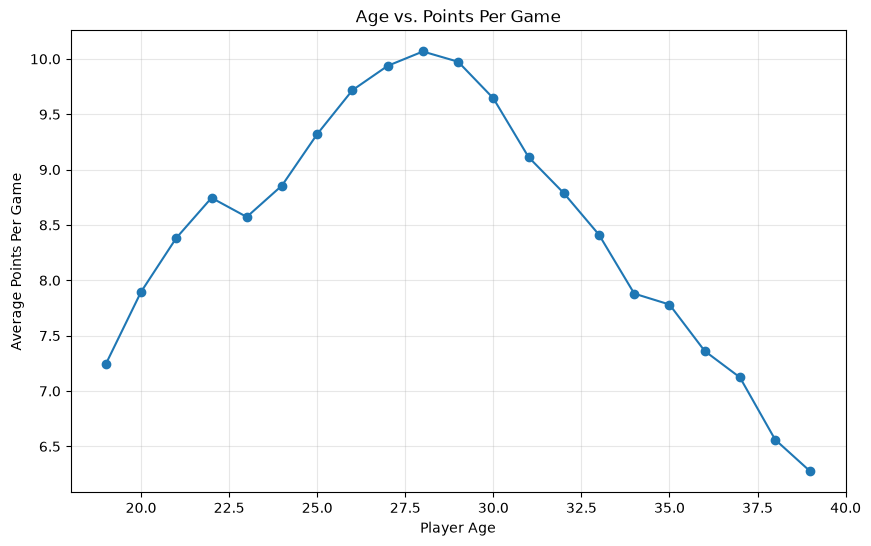

In [11]:
age_curve = df.groupby("PLAYER_AGE")["PTS_PER_GAME"].agg(["mean", "count"])
age_curve = age_curve[age_curve["count"] >= 30]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(age_curve.index, age_curve["mean"], marker="o")
ax.set_xlabel("Player Age")
ax.set_ylabel("Average Points Per Game")
ax.set_title("Age vs. Points Per Game") 
ax.grid(alpha=0.3)
plt.show()

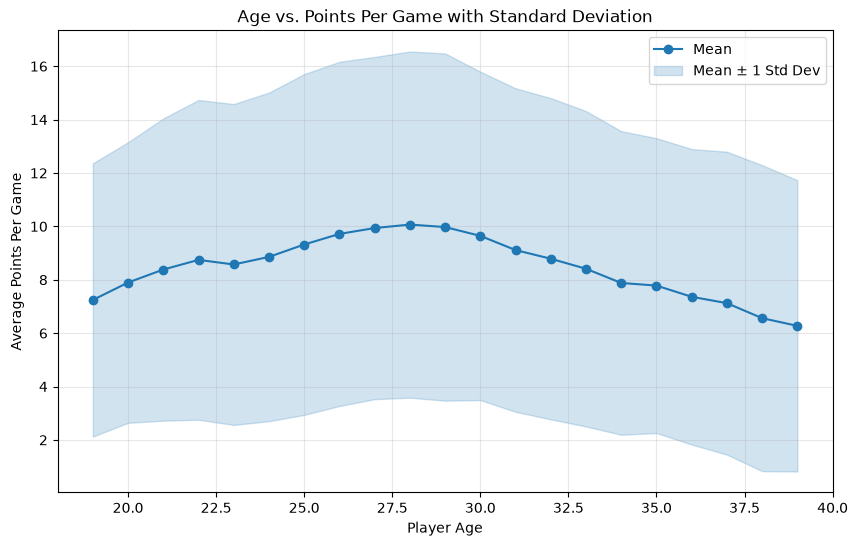

In [12]:
age_stats = df.groupby("PLAYER_AGE")["PTS_PER_GAME"].agg(["mean", "std", "count"])
age_stats = age_stats[age_stats["count"] >= 30]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(age_stats.index, age_stats["mean"], marker="o", color="C0", label="Mean")
ax.fill_between(age_stats.index, 
                age_stats["mean"] - age_stats["std"], 
                age_stats["mean"] + age_stats["std"], 
                color="C0", alpha=0.2, label="Mean ± 1 Std Dev")
ax.set_xlabel("Player Age")
ax.set_ylabel("Average Points Per Game")
ax.set_title("Age vs. Points Per Game with Standard Deviation")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

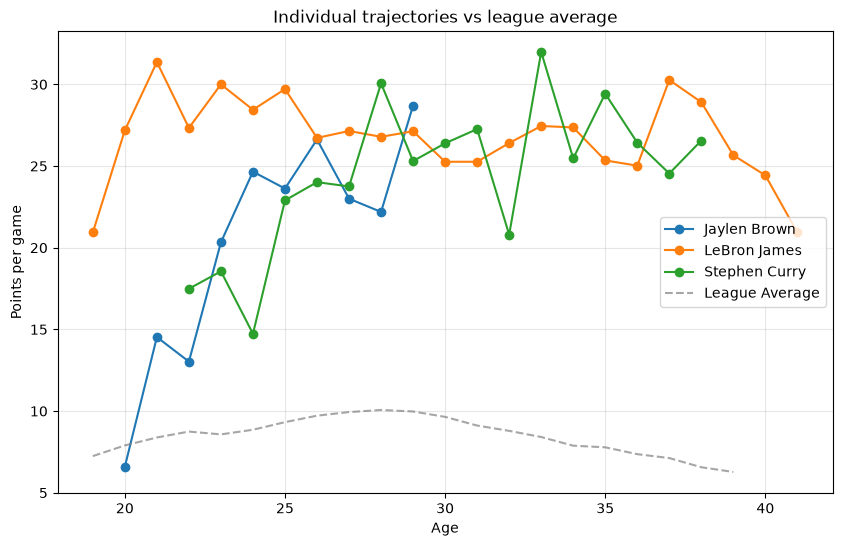

In [13]:
player_ids = {1627759: "Jaylen Brown", 2544: "LeBron James", 201939: "Stephen Curry"}  # adapte selon tes PLAYER_ID réels

fig, ax = matplotlib.pyplot.subplots(figsize=(10, 6))
for pid, name in player_ids.items():
    player_df = df[df["PLAYER_ID"] == pid].sort_values("PLAYER_AGE")
    ax.plot(player_df["PLAYER_AGE"], player_df["PTS_PER_GAME"], marker="o", label=name)

ax.plot(age_curve.index, age_curve["mean"], linestyle="--", color="gray", label="League Average", alpha=0.7)
ax.set_xlabel("Age")
ax.set_ylabel("Points per game")
ax.set_title("Individual trajectories vs league average")
ax.legend()
ax.grid(alpha=0.3)
matplotlib.pyplot.show()

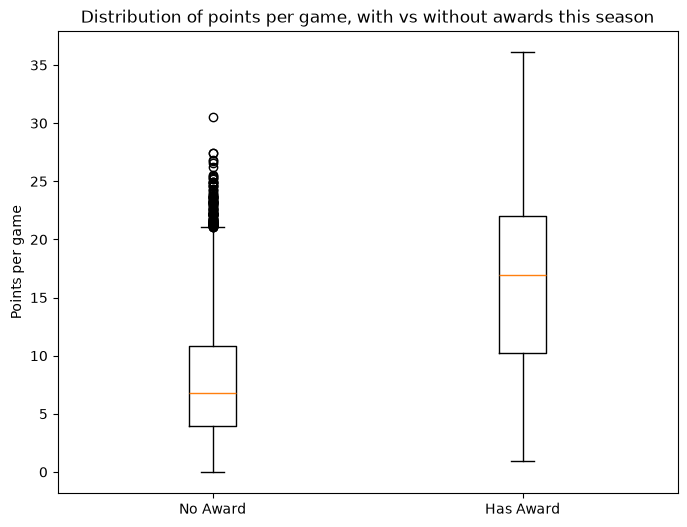

            count       mean       std       min        25%        50%  \
HAS_AWARD                                                                
False      9413.0   7.777955  4.933427  0.000000   3.973684   6.765957   
True       1613.0  16.509155  7.369931  0.909091  10.197531  16.974359   

                 75%        max  
HAS_AWARD                        
False      10.814815  30.543860  
True       22.024691  36.128205  


In [14]:
award_columns = [c for c in df.columns if c not in
                  ["PLAYER_ID", "SEASON_ID", "PLAYER_AGE", "GP", "GS", "MIN", "FGM", "FGA",
                   "FG_PCT", "FG3M", "FG3A", "FG3_PCT", "FTM", "FTA", "FT_PCT", "OREB", "DREB",
                   "REB", "AST", "STL", "BLK", "TOV", "PF", "PTS", "FIRST_NAME", "LAST_NAME",
                   "MIN_PER_GAME", "PTS_PER_GAME", "REB_PER_GAME", "AST_PER_GAME", "STL_PER_GAME", "BLK_PER_GAME", "TOV_PER_GAME", "PF_PER_GAME", "DREB_PER_GAME", "FGM_PER_GAME", "FGA_PER_GAME", "FG3M_PER_GAME", "FG3A_PER_GAME", "FTM_PER_GAME", "FTA_PER_GAME"]]

df["HAS_AWARD"] = df[award_columns].sum(axis=1) > 0

fig, ax = matplotlib.pyplot.subplots(figsize=(8, 6))
groups = [df.loc[~df["HAS_AWARD"], "PTS_PER_GAME"].dropna(), df.loc[df["HAS_AWARD"], "PTS_PER_GAME"].dropna()]
ax.boxplot(groups, tick_labels=["No Award", "Has Award"])
ax.set_ylabel("Points per game")
ax.set_title("Distribution of points per game, with vs without awards this season")
matplotlib.pyplot.show()

print(df.groupby("HAS_AWARD")["PTS_PER_GAME"].describe())

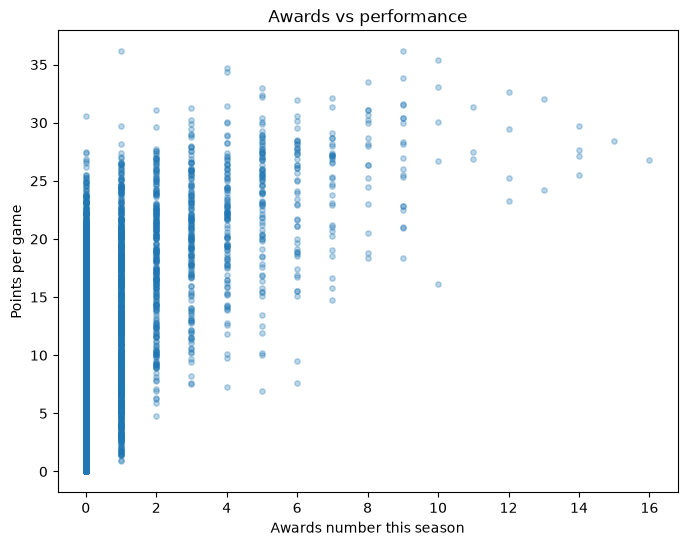

Correlation (Pearson) between number of awards and points per game: 0.532


In [15]:
df["AWARD_COUNT"] = df[award_columns].sum(axis=1)

fig, ax = matplotlib.pyplot.subplots(figsize=(8, 6))
ax.scatter(df["AWARD_COUNT"], df["PTS_PER_GAME"], alpha=0.3, s=15)
ax.set_xlabel("Awards number this season")
ax.set_ylabel("Points per game")
ax.set_title("Awards vs performance")
matplotlib.pyplot.show()

correlation = df["AWARD_COUNT"].corr(df["PTS_PER_GAME"])
print(f"Correlation (Pearson) between number of awards and points per game: {correlation:.3f}")

## Analysis

**Age evolution**: The ppg mean steadily grows until mid 20s-early 30s then declines as players get older. Although there are outliers to this "phenomenon".

**Awards vs Perf**: Players with no awards in a season have a lower median when compared to players with awards. We can notice some outliers here too given that awrds are mostly unique and players can have high scoring stats with no awards. Same, the mean difference is not as great as we could think because some awards are not tied to scoring performance (Sportsmanship, DPOY, ...)

I want to see how my model would apprehend the dataframe and if he would be able to understand thoses nuances. The awards are not to be predicted although I wonder if my model would be able to predict a player as MVP if he has never been selected for that role or if he would not end up giving the MVP awards to the same players over and over again (Jokic, Lebron, SGA, ...)

In [ ]:
df.drop(columns=["MIN", "DREB", "REB", "AST", "STL", "BLK", "TOV", "PF", "PTS", "FIRST_NAME", "LAST_NAME"], inplace=True)
df 

,PLAYER_ID,SEASON_ID,PLAYER_AGE,GP,GS,FGM,FGA,FG_PCT,FG3M,FG3A,FG3_PCT,FTM,FTA,FT_PCT,OREB,All_NBA_Team--,All_NBA_Team--1,All_NBA_Team--2,All_NBA_Team--3,Eastern Conference Finals Most Valuable Player,Hall of Fame Inductee,IBM Award,J. Walter Kennedy Citizenship,NBA All-Star,NBA All-Star Most Valuable Player,NBA All-Star Selection,NBA Champion,NBA Clutch Player of the Year,NBA Comeback Player of the Year,NBA Cup Most Valuable Player,NBA Defensive Player of the Month,NBA Defensive Player of the Year,NBA Finals Most Valuable Player,NBA Most Improved Player,NBA Most Valuable Player,NBA Player of the Month,NBA Player of the Week,NBA Rookie of the Month,NBA Rookie of the Year,NBA Sixth Man of the Year,NBA Sporting News Most Valuable Player of the Year,NBA Sporting News Rookie of the Year,NBA Sportsmanship,Olympic Appearance,Olympic Bronze Medal,Olympic Gold Medal,Olympic Silver Medal,Western Conference Finals Most Valuable Player,MIN_PER_GAME,DREB_PER_GAME,REB_PER_GAME,AST_PER_GAME,STL_PER_GAME,BLK_PER_GAME,TOV_PER_GAME,PF_PER_GAME,PTS_PER_GAME,HAS_AWARD,AWARD_COUNT
2,1886,2000-01,20.0,59,7,66,186,0.355,11,41,0.268,50,68,0.735,14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.728814,1.016949,1.254237,0.542373,0.118644,0.474576,0.711864,1.237288,3.271186,False,0.0
3,1886,2001-02,21.0,78,17,198,460,0.43,45,125,0.36,140,181,0.773,64,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21.102564,2.307692,3.128205,0.794872,0.24359,0.628205,1.230769,1.884615,7.448718,False,0.0
4,1886,2002-03,22.0,46,2,112,254,0.441,19,53,0.358,60,84,0.714,42,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,17.804348,1.978261,2.891304,0.913043,0.173913,1.217391,0.913043,1.869565,6.586957,False,0.0
5,1886,2003-04,23.0,21,0,50,106,0.472,9,22,0.409,39,47,0.83,9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.857143,1.47619,1.904762,0.428571,0.238095,0.52381,1.571429,1.095238,7.047619,False,0.0
6,1886,2004-05,24.0,7,0,16,40,0.4,1,5,0.2,3,6,0.5,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.285714,1.285714,2.0,0.571429,0.142857,0.285714,1.428571,1.285714,5.142857,False,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31073,201944,2012-13,26.0,24,0,48,97,0.495,5,15,0.333,9,21,0.429,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.25,1.666667,1.833333,1.583333,0.458333,0.083333,0.916667,0.541667,4.583333,False,0.0
31078,201603,2008-09,22.0,12,0,8,25,0.32,0,3,0.0,3,8,0.375,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.583333,0.333333,0.333333,0.25,0.083333,0.0,0.5,0.666667,1.583333,False,0.0
31079,201603,2009-10,23.0,69,19,236,458,0.515,2,15,0.133,44,64,0.688,42,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.826087,2.173913,2.782609,1.463768,0.565217,0.362319,0.942029,1.826087,7.507246,False,0.0
31080,201603,2010-11,24.0,59,28,228,513,0.444,17,61,0.279,72,94,0.766,39,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23.949153,1.932203,2.59322,1.762712,0.576271,0.033898,1.457627,1.474576,9.237288,False,0.0
